# Roche geometry comparisons — paper Figure 8

This notebook generates the numerical and approximate areas for both panels
of Figure 8: the L1 nozzle cross-section and the donor equipotential surface.
The plotting cells save PNGs to `paper_figures/` below the working directory.

Run all cells sequentially with Python 3, NumPy, SciPy, Matplotlib, and Numba.
No project data files or other notebooks are required. The first numerical
call compiles the Numba helpers; the full surface scan is the costly stage.

## Conventions

Lengths are in units of the separation $a$ and areas in $a^2$. The internal
mass ratio is `q = Ma/Md`; plot legends use $q_{\rm paper}=M_d/M_a$ with values
10, 2, and 1. The code evaluates the positive Roche potential
$\Omega=-\phi'=-\phi a/(G M_d)$, shown as $-\phi'$ on the horizontal axes.

The settings cell controls the potential and spatial grids. Each mass ratio
is evaluated at 50 potentials, and the comparison sphere radius is selected
from 500 samples. Cached contour rings and compiled searches reduce repeated
potential evaluations.

In [2]:
from pathlib import Path
import numpy as np
from scipy.optimize import brentq
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
from numba import njit

OUTPUT_DIR = Path("./paper_figures")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

mpl.rcParams.update({
    "text.usetex": False,
    "axes.formatter.use_mathtext": True,
    "font.family": "STIXGeneral",
    "mathtext.fontset": "cm",
    "axes.unicode_minus": False,
    "axes.linewidth": 1.5,
})

# Paper-resolution settings. Internal q is Ma/Md, not the displayed ratio.
Q_INTERNAL = [0.1, 0.5, 1.0]
N_POTENTIALS = 50
NOZZLE_ANGULAR_STEP = 1e-3       # radians
NOZZLE_RADIAL_STEP = 1e-3        # units of a
SURFACE_ANGULAR_STEP = 2.5e-3    # radians
SURFACE_GRID_STEP = 2.5e-3       # units of a, for x and radius
N_SPHERE_RADII = 500


## Dimensionless geometry and numerical methods

`first_crossing_index` locates the first sign-change interval of the radial
grid, including exact-zero crossings. The positive potential along a ray has
at most one minimum, allowing a minimum search followed by a binary search.
`refined_contour_radius` then bisects the bracket to an absolute tolerance
of $10^{-12}a$.

The surface is triangulated between adjacent contour rings using Heron's
formula. Above L1 it measures the curved donor-side boundary truncated at
the L1 plane, without a plane cap. The axial and angular boundary strips
omitted by the sampling grids contribute to the finite-resolution error.

In [2]:
def roche_potential(x, y, z, q):
    """Positive Ω=-φa/(G Md); q=Ma/Md, donor at x=0, accretor x=1."""
    x_cm = q / (1.0 + q)
    r1 = np.sqrt(x**2 + y**2 + z**2)
    r2 = np.sqrt((x - 1.0)**2 + y**2 + z**2)
    return 1.0/r1 + q/r2 + 0.5*(1.0 + q)*((x - x_cm)**2 + y**2)


@njit
def roche_potential_aroundx(x, r, theta, q):
    """Same positive potential on a ray around the binary x axis."""
    y = r * np.cos(theta)
    z = r * np.sin(theta)
    x_cm = q / (1.0 + q)
    r1 = np.sqrt(x**2 + y**2 + z**2)
    r2 = np.sqrt((x - 1.0)**2 + y**2 + z**2)
    return 1.0/r1 + q/r2 + 0.5*(1.0 + q)*((x - x_cm)**2 + y**2)


def find_lagrange_point(q, outer=False, tol=1e-10):
    """Root of dΩ/dx; L1 between stars or outer point at x>1.

    For the q<=1 grid, x>1 is the L2 point behind the
    less massive accretor. Coordinates and potential are dimensionless.
    """
    def derivative(x):
        return (-x/abs(x)**3 - q*(x-1.0)/abs(x-1.0)**3
                + (1.0+q)*(x-q/(1.0+q)))
    bracket = (1.0+1e-6, 5.0) if outer else (1e-6, 1.0-1e-6)
    return brentq(derivative, *bracket, xtol=tol)


def find_L1(q):
    return find_lagrange_point(q)


def find_L2(q):
    return find_lagrange_point(q, outer=True)


def find_x_tip(omega_target, q, x_max=-1e-6, x_min=-2.0, n_scan=20000):
    """Discrete axial scan: first local minimum of |Ω-target|.

    Select the boundary from a 20,000-point grid. x_max/x_min also
    bracket the inward-facing donor tip for detached equipotentials.
    """
    x_scan = np.linspace(x_max, x_min, n_scan)
    # A scan may include the point-mass singularity at x=0; infinity
    # cannot be the selected residual minimum.
    with np.errstate(divide="ignore"):
        residual = np.abs(roche_potential(x_scan, 0.0, 0.0, q)-omega_target)
    for i in range(1, len(residual)-1):
        if residual[i+1] > residual[i] and residual[i] < residual[i-1]:
            return x_scan[i]
    return x_scan[np.argmin(residual)]


def roche_lobe_radius(q):
    """Eggleton donor radius in units of a; internal q is Ma/Md."""
    q23, q13 = q**(-2/3), q**(-1/3)
    return 0.49*q23/(0.6*q23 + np.log(1+q13))


def potential_rv_dimensionless(radius, q):
    """Positive Jackson volume-radius expansion Ω(r), radius in units a.

    The expansion is extrapolated above L1. Its sphere area is compared
    with the numerically triangulated donor-side surface.
    """
    a1 = (1/3)*(1.0+q)
    a2 = (4/45)*((1.0+q)**2 + 9*q**2 + 3*q*(1.0+q))
    constant = q + q/(2.0*(1.0+1.0/q))
    return constant + 1.0/radius + a1*radius**2 + a2*radius**5


def nozzle_coefficients(q):
    """C1,C2,C3 of the negative Roche potential at L1 (dimensionless).

    Ω=-φ', so the expanding nozzle coordinate is Δφ'=Ω_L1-Ω>=0.
    """
    x = find_L1(q)
    g3 = 1.0/x**3 + q/(1.0-x)**3
    g5 = 1.0/x**5 + q/(1.0-x)**5
    return (g3-q-1.0)/2.0, g3/2.0, -3.0*g5/8.0


@njit
def first_crossing_index(x, theta, q, omega_target, rgrid):
    """First sign-changing radial-grid interval, with no interpolation.

    Ω(r) decreases then increases (or decreases throughout): its radial
    derivative divided by r is a constant minus two decreasing gravity
    terms. A discrete minimum search followed by binary search locates
    the first crossing bracket, including exact-zero crossings.
    """
    lo, hi = 0, len(rgrid)-1
    # Find a minimum of the unimodal discrete potential in O(log N).
    while hi-lo > 4:
        a = lo+(hi-lo)//3
        b = hi-(hi-lo)//3
        va = roche_potential_aroundx(x, rgrid[a], theta, q)
        vb = roche_potential_aroundx(x, rgrid[b], theta, q)
        if va <= vb:
            hi = b
        else:
            lo = a
    imin = lo
    vmin = roche_potential_aroundx(x, rgrid[lo], theta, q)
    for i in range(lo+1, hi+1):
        value = roche_potential_aroundx(x, rgrid[i], theta, q)
        if value < vmin:
            imin, vmin = i, value
    f0 = roche_potential_aroundx(x, rgrid[0], theta, q)-omega_target
    if f0 == 0.0:
        for i in range(len(rgrid)-1):
            left = roche_potential_aroundx(x, rgrid[i], theta, q)-omega_target
            right = roche_potential_aroundx(x, rgrid[i+1], theta, q)-omega_target
            if np.sign(left) != np.sign(right):
                return i
        raise ValueError('No radial sign change')
    if f0 > 0.0:
        if vmin > omega_target:
            raise ValueError('No radial sign change')
        lo, hi = 0, imin
        while hi-lo > 1:
            mid = (lo+hi)//2
            if roche_potential_aroundx(x, rgrid[mid], theta, q) <= omega_target:
                hi = mid
            else:
                lo = mid
        return hi-1
    # If the scan begins outside the inner boundary, select the
    # first crossing on the rising branch.
    lo, hi = imin, len(rgrid)-1
    if roche_potential_aroundx(x, rgrid[hi], theta, q) < omega_target:
        raise ValueError('No radial sign change')
    while hi-lo > 1:
        mid = (lo+hi)//2
        if roche_potential_aroundx(x, rgrid[mid], theta, q) >= omega_target:
            hi = mid
        else:
            lo = mid
    return hi-1


@njit
def refined_contour_radius(x, theta, q, omega_target, rgrid):
    """Resolve the first radial crossing with a smooth bracketed root.

    The coarse radial grid identifies the first crossing bracket.
    Bisection resolves the contour radius within that bracket to an
    absolute tolerance of 1e-12 in units of a.
    """
    index = first_crossing_index(x, theta, q, omega_target, rgrid)
    left, right = rgrid[index], rgrid[index+1]
    fleft = roche_potential_aroundx(x, left, theta, q)-omega_target
    fright = roche_potential_aroundx(x, right, theta, q)-omega_target
    if fleft == 0.0:
        return left
    if fright == 0.0:
        return right
    for _ in range(64):
        middle = 0.5*(left+right)
        fmiddle = roche_potential_aroundx(x, middle, theta, q)-omega_target
        if fmiddle == 0.0 or right-left <= 1e-12:
            return middle
        if np.sign(fleft) != np.sign(fmiddle):
            right = middle
        else:
            left, fleft = middle, fmiddle
    return 0.5*(left+right)


@njit
def ring_coordinates(x, omega_target, q, angular_grid, rgrid):
    """Smooth first-quadrant contour at one x; lengths in units of a."""
    y, z = np.empty(len(angular_grid)), np.empty(len(angular_grid))
    for j in range(len(angular_grid)):
        theta = angular_grid[j]
        radius = refined_contour_radius(x, theta, q, omega_target, rgrid)
        y[j], z[j] = radius*np.cos(theta), radius*np.sin(theta)
    return y, z


@njit
def numerical_nozzle_area_fromL1(q, omega, x_l1, angular_spacing=1e-3, grid_spacing=1e-3):
    """Polygon-area sum with refined contour radii in the L1 plane, normalized by a².

    The angular grid excludes θ=0 and π/2. Adjacent contour coordinates
    are cached for the polygon sum.
    """
    angles = np.arange(angular_spacing, np.pi/2.0, angular_spacing)
    rgrid = np.arange(0.0, 3.0, grid_spacing)
    y, z = ring_coordinates(x_l1, omega, q, angles, rgrid)
    area = 0.0
    for j in range(len(angles)-1):
        area += 0.5*abs(y[j]*z[j+1]-y[j+1]*z[j])
    return 4.0*area


@njit
def donor_surface_area(omega, q, x_right, x_left, angular_spacing=2.5e-3, grid_spacing=2.5e-3):
    """Triangulated donor-side curved area with smooth radial boundaries in units of a².

    The axial grid starts at x_left+1e-4. Heron's formula sums triangles
    between contour rings, with the axial/angular boundary strips omitted.
    Radial boundaries are resolved within their first-crossing brackets.
    Above L1, x_right=x_L1 truncates the surface without a nozzle-plane cap.
    Ring coordinates are cached between adjacent axial samples.
    """
    xgrid = np.arange(x_left+1e-4, x_right, grid_spacing)
    angles = np.arange(angular_spacing, np.pi/2.0, angular_spacing)
    rgrid = np.arange(0.0, 3.0, grid_spacing)
    if len(xgrid) < 2:
        return 0.0
    y, z = ring_coordinates(xgrid[0], omega, q, angles, rgrid)
    area = 0.0
    for i in range(len(xgrid)-1):
        yp, zp = ring_coordinates(xgrid[i+1], omega, q, angles, rgrid)
        dx2 = (xgrid[i]-xgrid[i+1])**2
        strips = 0.0
        for j in range(len(angles)-1):
            a1 = np.sqrt((y[j+1]-y[j])**2+(z[j+1]-z[j])**2)
            b1 = np.sqrt((y[j]-yp[j])**2+(z[j]-zp[j])**2+dx2)
            diagonal = np.sqrt((y[j+1]-yp[j])**2+(z[j+1]-zp[j])**2+dx2)
            a2 = np.sqrt((yp[j+1]-yp[j])**2+(zp[j+1]-zp[j])**2)
            b2 = np.sqrt((y[j+1]-yp[j+1])**2+(z[j+1]-zp[j+1])**2+dx2)
            s1 = 0.5*(a1+b1+diagonal)
            s2 = 0.5*(a2+b2+diagonal)
            strips += (np.sqrt(s1*(s1-a1)*(s1-b1)*(s1-diagonal))
                       +np.sqrt(s2*(s2-a2)*(s2-b2)*(s2-diagonal)))
        area += strips
        y, z = yp, zp
    return 4.0*area


## Figure 8, right panel — nozzle cross-section

The potential runs from L1 to the outer point at `x > 1`. For the internal
mass ratios `q = Ma/Md <= 1`, this is L2 behind the less massive accretor.
The nozzle area is a polygon sum in the L1 plane. The comparison curve
integrates the first-order approximation to $dA_N/d\phi$ over the same
potential interval.

In [3]:
q_grid = Q_INTERNAL
phi_l1s = np.zeros(len(q_grid))
phi_l2s = np.zeros(len(q_grid))
phi_phis = np.zeros((len(q_grid), N_POTENTIALS))
area_phis = np.zeros_like(phi_phis)

for qi, q in enumerate(q_grid):
    x_l1 = find_L1(q)
    phi_l1s[qi] = roche_potential(x_l1, 0.0, 0.0, q)
    phi_l2s[qi] = roche_potential(find_L2(q), 0.0, 0.0, q)
    phi_phis[qi] = np.linspace(phi_l1s[qi], phi_l2s[qi], N_POTENTIALS)
    for pi, omega in enumerate(phi_phis[qi]):
        area_phis[qi, pi] = numerical_nozzle_area_fromL1(
            q, omega, x_l1, NOZZLE_ANGULAR_STEP, NOZZLE_RADIAL_STEP
        )
    print(f"Nozzle complete: manuscript q={1/q:g}")


Nozzle complete: manuscript q=10
Nozzle complete: manuscript q=2
Nozzle complete: manuscript q=1


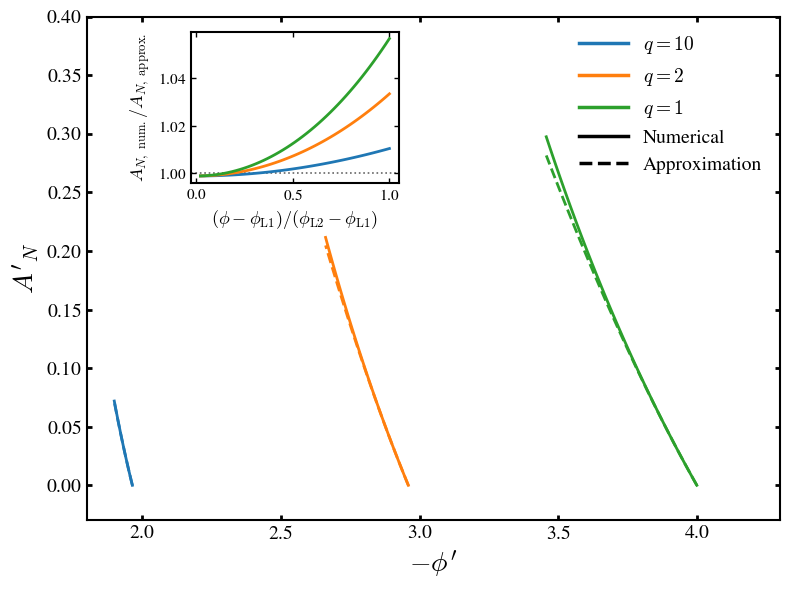

In [4]:
qinds = [0, 1, 2]
cols = ['C0', 'C1', 'C2']
fig, ax = plt.subplots(figsize=(8, 6))
axins = ax.inset_axes([0.15, 0.67, 0.3, 0.3])
for qind, col in zip(qinds, cols):
    areaB, areaC, C3 = nozzle_coefficients(q_grid[qind])
    phi = phi_phis[qind, :]
    area_numerical = area_phis[qind, :]
    delta_phi = phi_l1s[qind] - phi
    areafact1 = np.pi / np.sqrt(areaB * areaC)
    areafact2 = areafact1 * (C3 * (3.0 * areaB ** 2 + 2.0 * areaB * areaC + 3.0 * areaC ** 2) / (4.0 * areaB ** 2 * areaC ** 2))
    area_approx = areafact1 * delta_phi - 0.5 * areafact2 * delta_phi ** 2
    ax.plot(phi, area_numerical, color=col, linestyle='-', linewidth=2)
    ax.plot(phi, area_approx, color=col, linestyle='--', linewidth=2)
    valid = np.isfinite(area_numerical) & np.isfinite(area_approx) & (np.abs(area_approx) > 1e-14)
    axins.plot((phi[valid] - phi_l1s[qind]) / (phi_l2s[qind] - phi_l1s[qind]), area_numerical[valid] / area_approx[valid], color=col, linestyle='-', linewidth=2)
ax.tick_params(which='both', direction='in', top=True, right=True, labelsize=14, width=2)
ax.set_xlabel("$-\\phi'$", fontsize=20)
ax.set_ylabel("$A'_N$", fontsize=20)
axins.tick_params(which='both', direction='in', top=True, right=True, labelsize=11, width=1.0)
axins.set_xlabel('$(\\phi-\\phi_{\\rm L1})/(\\phi_{\\rm L2}-\\phi_{\\rm L1})$', fontsize=13)
axins.set_ylabel('$A_{N,~\\rm num.}/A_{N,~\\rm approx.}$', fontsize=13)
axins.axhline(1.0, color='0.4', linestyle=':', linewidth=1.2, zorder=0)
color_handles = [Line2D([0], [0], color=col, linestyle='-', linewidth=2.5, label=f'$q={1.0/q_grid[qind]:g}$') for qind, col in zip(qinds, cols)]
style_handles = [Line2D([0], [0], color='black', linestyle='-', linewidth=2.5, label='Numerical'), Line2D([0], [0], color='black', linestyle='--', linewidth=2.5, label='Approximation')]
ax.legend(handles=color_handles + style_handles, loc='upper right', fontsize=14, frameon=True, handlelength=2.5, framealpha=0.0)
ax.set_ylim(-0.03, 0.4)
ax.set_xlim(1.8, 4.3)
plt.tight_layout()
fig.savefig(OUTPUT_DIR / 'nozzle_surfareas.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

## Figure 8, left panel — donor equipotential area

The potential grid runs from $\Omega_{L1}+3(\Omega_{L1}-\Omega_{L2})$ through
$\Omega_{L2}$. For detached equipotentials ($\Omega>\Omega_{L1}$), both donor
tips are found on the axial scan. At larger physical potentials, the right
boundary is the L1 plane.

The comparison sphere radius is the nearest potential match on a 500-point
grid from zero to twice the Eggleton radius. Its area is $4\pi r^2$.
The singular zero-radius potential is set to $+\infty$ and cannot be selected.
The Jackson expansion is extrapolated beyond L1; the radius search spans
both branches of its truncated polynomial.

In [5]:
q_evaluate = Q_INTERNAL
phi_counter = np.zeros((len(q_evaluate), N_POTENTIALS))
area_numerical = np.zeros_like(phi_counter)
area_approx = np.zeros_like(phi_counter)

for qi, q in enumerate(q_evaluate):
    xl1 = find_L1(q)
    phi_l1 = roche_potential(xl1, 0.0, 0.0, q)
    phi_l2 = roche_potential(find_L2(q), 0.0, 0.0, q)
    phi_counter[qi] = np.linspace(
        phi_l1 + 3*(phi_l1-phi_l2), phi_l2, N_POTENTIALS
    )

    radius_grid = np.linspace(0.0, 2.0*roche_lobe_radius(q), N_SPHERE_RADII)
    with np.errstate(divide="ignore"):
        sphere_potentials = potential_rv_dimensionless(radius_grid, q)
    nearest = np.abs(phi_counter[qi, :, None]-sphere_potentials[None, :]).argmin(axis=1)
    area_approx[qi] = 4.0*np.pi*radius_grid[nearest]**2

    for pi, omega in enumerate(phi_counter[qi]):
        x_left = find_x_tip(omega, q)
        x_right = (find_x_tip(omega, q, x_max=xl1, x_min=0.0)
                   if omega > phi_l1 else xl1)
        area_numerical[qi, pi] = donor_surface_area(
            omega, q, x_right, x_left, SURFACE_ANGULAR_STEP, SURFACE_GRID_STEP
        )
    print(f"Surface complete: manuscript q={1/q:g}")


Surface complete: manuscript q=10
Surface complete: manuscript q=2
Surface complete: manuscript q=1


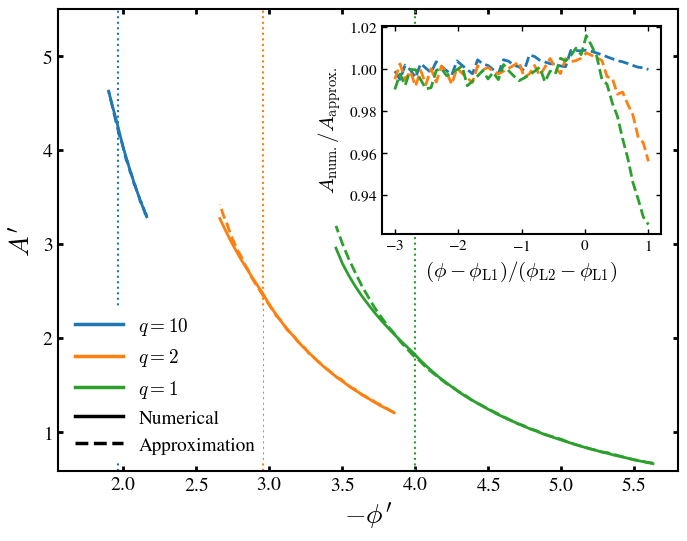

In [7]:
qinds = [0, 1, 2]
cols = ['C0', 'C1', 'C2']
fig, ax = plt.subplots(figsize=(8, 6))
for qind, col in zip(qinds, cols):
    ax.plot(phi_counter[qind, :], area_numerical[qind, :], color=col, linestyle='-', linewidth=2)
    ax.plot(phi_counter[qind, :], area_approx[qind, :], color=col, linestyle='--', linewidth=2)
axins = inset_axes(ax, width='45%', height='45%', loc='upper right', borderpad=1.2)
for qind, col in zip(qinds, cols):
    xl1 = find_L1(q_evaluate[qind])
    phi_l1 = roche_potential(xl1, 0.0, 0.0, q=q_evaluate[qind])
    xl2 = find_L2(q_evaluate[qind])
    phi_l2 = roche_potential(xl2, 0.0, 0.0, q=q_evaluate[qind])
    ax.axvline(phi_l1, c=col, linestyle=':')
    axins.plot((phi_counter[qind, :] - phi_l1) / (phi_l2 - phi_l1), area_numerical[qind, :] / area_approx[qind, :], color=col, linestyle='--', linewidth=2)
ax.tick_params(which='both', direction='in', top=True, right=True, labelsize=14, width=2)
ax.set_xlabel("$-\\phi'$", fontsize=20)
ax.set_ylabel("$A'$", fontsize=20)
ax.set_ylim(0.58, 5.5)
ax.set_xlim(1.55, 5.8)
axins.tick_params(which='both', direction='in', top=True, right=True, labelsize=11, width=1.0)
axins.set_xlabel('$(\\phi-\\phi_{\\rm L1})/(\\phi_{\\rm L2}-\\phi_{\\rm L1})$', fontsize=15)
axins.set_ylabel('$A_{\\rm num.}/A_{\\rm approx.}$', fontsize=15)
color_handles = [Line2D([0], [0], color=col, linestyle='-', linewidth=2.5, label=f'$q={1.0 / q_evaluate[qind]:g}$') for qind, col in zip(qinds, cols)]
style_handles = [Line2D([0], [0], color='black', linestyle='-', linewidth=2.5, label='Numerical'), Line2D([0], [0], color='black', linestyle='--', linewidth=2.5, label='Approximation')]
ax.legend(handles=color_handles + style_handles, loc='lower left', fontsize=13.8, frameon=True, handlelength=2.5, framealpha=1.0, edgecolor='none')
fig.savefig(OUTPUT_DIR / 'numerical_vs_approx_area_comp.png', dpi=200, bbox_inches='tight')
plt.show()
plt.close(fig)

## Plot interpretation and references

- Solid curves show numerical areas; dashed curves show the analytic approximations.
- Insets show the numerical-to-approximate area ratio against normalized potential.
- Both nozzle areas vanish at L1, so that point is excluded from the ratio inset.
- The donor-side surface is open at the L1 plane above contact; the comparison
  sphere is closed. Insets autoscale to display the full ratio range.

References: [Jackson et al. (2017)](https://arxiv.org/abs/1612.04332) and
[Marchant et al. (2021)](https://doi.org/10.1051/0004-6361/202039992).